In [2]:
!pip install -q langchain==0.2.17 langchain-core==0.2.43 langchain-community==0.2.17 langchain-openai==0.1.25 openai>=1.30.0 faiss-cpu tiktoken pypdf statsmodels gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.35.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
langgraph-prebuilt 1.0.5 requires langchain-core>=1.0.0, but you have langchain-core 0.2.43 which is incompatible.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incomp

In [1]:
import os
import json
import warnings
from datetime import datetime
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    cohen_kappa_score, classification_report,
    confusion_matrix, precision_recall_fscore_support
)

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# CORRECT IMPORTS - This is the key!
from langchain_community.document_loaders import PyPDFLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI  # ← Correct package!
from langchain_community.vectorstores import FAISS
from langchain.prompts import ChatPromptTemplate, PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

import gradio as gr
from tqdm.notebook import tqdm

# Settings
warnings.filterwarnings('ignore')
plt.style.use('default')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
np.random.seed(42)

print("✅ All libraries imported successfully!")
print(f"📊 NumPy: {np.__version__}")
print(f"🐼 Pandas: {pd.__version__}")

✅ All libraries imported successfully!
📊 NumPy: 1.26.4
🐼 Pandas: 2.2.2


In [2]:
import os

print("🔑 Enter your OpenAI API Key:")
print("Get it from: https://platform.openai.com/api-keys\n")

OPENAI_API_KEY = ""

# Set as environment variable - this is the correct way!
os.environ['OPENAI_API_KEY'] = OPENAI_API_KEY

if OPENAI_API_KEY:
    print(f"\n✅ API Key configured! ({len(OPENAI_API_KEY)} characters)")
else:
    print("\n❌ No API key provided!")

🔑 Enter your OpenAI API Key:
Get it from: https://platform.openai.com/api-keys


✅ API Key configured! (164 characters)


In [3]:
from google.colab import files

print("📄 Upload your Behavioral Economics PDF:")
uploaded = files.upload()

pdf_filename = list(uploaded.keys())[0]
print(f"\n✅ Uploaded: {pdf_filename}")

📄 Upload your Behavioral Economics PDF:


Saving Susceptibility of Mental Accounting Principles - Session3.pdf to Susceptibility of Mental Accounting Principles - Session3.pdf
Saving Neuroimage article - Regret and disappointment.pdf to Neuroimage article - Regret and disappointment.pdf
Saving Zeelenberg and Pieters, 2007 - Theory of regret regulation 1.0.pdf to Zeelenberg and Pieters, 2007 - Theory of regret regulation 1.0.pdf
Saving Kirmani and Rao-2000-JM-No Pain No Gain.pdf to Kirmani and Rao-2000-JM-No Pain No Gain.pdf

✅ Uploaded: Susceptibility of Mental Accounting Principles - Session3.pdf


In [4]:
# Load PDF
print(f"📖 Loading PDF...")
loader = PyPDFLoader(pdf_filename)
documents = loader.load()
print(f"✅ Loaded {len(documents)} pages")

# Split into chunks
print("\n🔨 Creating chunks...")
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

text_chunks = text_splitter.split_documents(documents)
print(f"✅ Created {len(text_chunks)} chunks")

📖 Loading PDF...
✅ Loaded 19 pages

🔨 Creating chunks...
✅ Created 164 chunks


In [6]:
!pip install -U langchain langchain-community langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.2/102.2 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 112.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 71.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 475.9/475.9 kB 47.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.1/413.1 kB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 76.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.7/64.7 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 75.1 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: tiktoken
    Found existing installation: tiktoken 0.5.2
    Uninstalling tiktoken-0.5.2:
      Successfu

In [5]:
# Initialize embeddings - reads from environment variable automatically
print("🔧 Initializing embeddings...")
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# Build FAISS vectorstore
print("🏗️ Building vector database...")
vectorstore = FAISS.from_documents(text_chunks, embeddings)

# Create retriever with SIMILARITY search (not MMR to avoid simsimd issues)
retriever = vectorstore.as_retriever(
    search_type="similarity",  # Changed from "mmr"
    search_kwargs={"k": 5}
)

print("✅ Vector database ready!")

🔧 Initializing embeddings...
🏗️ Building vector database...
✅ Vector database ready!


In [6]:
# Initialize GPT-4o - reads from environment variable automatically
print("🤖 Initializing GPT-4o...")
llm = ChatOpenAI(
    model="gpt-4o",
    temperature=0
)

print("✅ Language model ready!")

🤖 Initializing GPT-4o...
✅ Language model ready!


In [7]:
test_review = "I wish I had taken that job offer when I had the chance; I would be in a much better position now."

print("🧪 Testing classification...")
print(f"Review: {test_review}\n")

# Create prompt
prompt = ChatPromptTemplate.from_template(
    """You are an expert in behavioral economics.

Context from literature:
{context}

Customer Review:
{question}

REGRET: Personal responsibility, "I should have done differently"
DISAPPOINTMENT: External factors, "It should have been better"

Respond with JSON only:
{{"emotion": "REGRET" or "DISAPPOINTMENT", "confidence": 0.X}}
"""
)

# Build chain
chain = (
    {"context": retriever, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)

# Classify
response = chain.invoke(test_review)

# Clean response
response_clean = response.strip()
if response_clean.startswith("```json"):
    response_clean = response_clean.split("```json")[1].split("```")[0].strip()
elif response_clean.startswith("```"):
    response_clean = response_clean.split("```")[1].split("```")[0].strip()

result = json.loads(response_clean)

print(f"📊 Result:")
print(f"  Emotion: {result['emotion']}")
print(f"  Confidence: {result['confidence']:.1%}")
print("\n✅ Classification working!")

🧪 Testing classification...
Review: I wish I had taken that job offer when I had the chance; I would be in a much better position now.

📊 Result:
  Emotion: REGRET
  Confidence: 90.0%

✅ Classification working!


In [8]:
print("📊 Upload your Customer Reviews CSV:")
uploaded_csv = files.upload()

csv_filename = list(uploaded_csv.keys())[0]
df = pd.read_csv(csv_filename)

print(f"\n✅ Loaded: {csv_filename}")
print(f"📊 Shape: {df.shape}")
print(f"\n📋 Columns: {list(df.columns)}")
df.head()

📊 Upload your Customer Reviews CSV:


Saving Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv to Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv

✅ Loaded: Datafiniti_Amazon_Consumer_Reviews_of_Amazon_Products_May19.csv
📊 Shape: (28332, 24)

📋 Columns: ['id', 'dateAdded', 'dateUpdated', 'name', 'asins', 'brand', 'categories', 'primaryCategories', 'imageURLs', 'keys', 'manufacturer', 'manufacturerNumber', 'reviews.date', 'reviews.dateSeen', 'reviews.didPurchase', 'reviews.doRecommend', 'reviews.id', 'reviews.numHelpful', 'reviews.rating', 'reviews.sourceURLs', 'reviews.text', 'reviews.title', 'reviews.username', 'sourceURLs']


,id,dateAdded,dateUpdated,name,asins,brand,categories,primaryCategories,imageURLs,keys,manufacturer,manufacturerNumber,reviews.date,reviews.dateSeen,reviews.didPurchase,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.username,sourceURLs
0,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",AmazonBasics,HL-002619,2017-03-02T00:00:00.000Z,2017-08-28T00:00:00Z,NaN,NaN,NaN,NaN,3,https://www.amazon.com/product-reviews/B00QWO9...,I order 3 of them and one of the item is bad q...,... 3 of them and one of the item is bad quali...,Byger yang,"https://www.barcodable.com/upc/841710106442,ht..."
1,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",AmazonBasics,HL-002619,2016-08-31T00:00:00.000Z,2017-08-28T00:00:00Z,NaN,NaN,NaN,NaN,4,https://www.amazon.com/product-reviews/B00QWO9...,Bulk is always the less expensive way to go fo...,... always the less expensive way to go for pr...,ByMG,"https://www.barcodable.com/upc/841710106442,ht..."
2,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",AmazonBasics,HL-002619,2016-12-06T00:00:00.000Z,2017-08-28T00:00:00Z,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,Well they are not Duracell but for the price i...,... are not Duracell but for the price i am ha...,BySharon Lambert,"https://www.barcodable.com/upc/841710106442,ht..."
3,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",AmazonBasics,HL-002619,2016-03-28T00:00:00.000Z,2017-08-28T00:00:00Z,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,Seem to work as well as name brand batteries a...,... as well as name brand batteries at a much ...,Bymark sexson,"https://www.barcodable.com/upc/841710106442,ht..."
4,AVpgNzjwLJeJML43Kpxn,2015-10-30T08:59:32Z,2019-04-25T09:08:16Z,AmazonBasics AAA Performance Alkaline Batterie...,"B00QWO9P0O,B00LH3DMUO",Amazonbasics,"AA,AAA,Health,Electronics,Health & Household,C...",Health & Beauty,https://images-na.ssl-images-amazon.com/images...,"amazonbasics/hl002619,amazonbasicsaaaperforman...",AmazonBasics,HL-002619,2017-04-22T00:00:00.000Z,2017-08-28T00:00:00Z,NaN,NaN,NaN,NaN,5,https://www.amazon.com/product-reviews/B00QWO9...,These batteries are very long lasting the pric...,... batteries are very long lasting the price ...,Bylinda,"https://www.barcodable.com/upc/841710106442,ht..."


In [9]:
print("🧹 Preprocessing...\n")

df_analysis = df[[
    'id', 'reviews.rating', 'primaryCategories',
    'reviews.text', 'reviews.date'
]].copy()

print(f"Initial: {len(df_analysis)}")

df_analysis = df_analysis[df_analysis['reviews.rating'] <= 3]
print(f"After rating filter: {len(df_analysis)}")

df_analysis = df_analysis.dropna(subset=['reviews.text'])
df_analysis = df_analysis.drop_duplicates(subset=['reviews.text'])
print(f"After cleaning: {len(df_analysis)}")

df_analysis['reviews.date'] = pd.to_datetime(df_analysis['reviews.date'], errors='coerce')
df_analysis = df_analysis.reset_index(drop=True)

print(f"\n✅ Final: {len(df_analysis)} reviews")

🧹 Preprocessing...

Initial: 28332
After rating filter: 2787
After cleaning: 2019

✅ Final: 2019 reviews


In [10]:
SAMPLE_SIZE = 100  # ← Change this!

print(f"⚙️ Will process {SAMPLE_SIZE} reviews")
print(f"⏱️ Estimated time: ~{SAMPLE_SIZE * 2 / 60:.0f} minutes")

⚙️ Will process 100 reviews
⏱️ Estimated time: ~3 minutes


In [11]:
df_sample = df_analysis.sample(
    n=min(SAMPLE_SIZE, len(df_analysis)),
    random_state=42
)

print(f"🎯 Classifying {len(df_sample)} reviews...\n")

classification_prompt = ChatPromptTemplate.from_template(
    """You are an expert in behavioral economics.

Context: {context}
Review: {question}

REGRET: Personal responsibility, "I should have..."
DISAPPOINTMENT: External factors, "It should have..."

Respond with JSON only:
{{"emotion": "REGRET" or "DISAPPOINTMENT", "confidence": 0.X}}
"""
)

classification_chain = (
    {"context": retriever, "question": RunnablePassthrough()}
    | classification_prompt
    | llm
    | StrOutputParser()
)

results = []
for idx, row in tqdm(df_sample.iterrows(), total=len(df_sample)):
    try:
        response = classification_chain.invoke(row['reviews.text'])

        # Clean response
        clean = response.strip()
        if clean.startswith("```"):
            clean = clean.split("```")[1].replace("json", "").strip()

        result = json.loads(clean)
        results.append({
            'emotion': result.get('emotion', 'DISAPPOINTMENT'),
            'confidence': result.get('confidence', 0.5)
        })
    except:
        results.append({'emotion': 'ERROR', 'confidence': 0.0})

df_results = pd.concat([
    df_sample.reset_index(drop=True),
    pd.DataFrame(results)
], axis=1)

df_results.rename(columns={'emotion': 'result'}, inplace=True)

print("\n✅ Done!")
print(df_results['result'].value_counts())

🎯 Classifying 100 reviews...



  0%|          | 0/100 [00:00<?, ?it/s]


✅ Done!
result
DISAPPOINTMENT    84
REGRET            16
Name: count, dtype: int64


In [12]:
print("📈 Calculating RDS scores...")

rds_prompt = PromptTemplate(
    template="""Rate this review (1-7 scale):

Review: {text}

1. Counterfactual Thinking (1=none, 7=extensive)
2. Personal Responsibility (1=external, 7=personal)
3. Controllability (1=uncontrollable, 7=controllable)
4. Negative Affect (1=mild, 7=intense)

JSON only:
{{"counterfactual": X, "responsibility": X, "controllability": X, "affect": X}}
""",
    input_variables=["text"]
)

rds_scores = []
for idx, row in tqdm(df_results.iterrows(), total=len(df_results)):
    try:
        chain = rds_prompt | llm | StrOutputParser()
        response = chain.invoke({"text": row['reviews.text']})

        clean = response.strip()
        if clean.startswith("```"):
            clean = clean.split("```")[1].replace("json", "").strip()

        scores = json.loads(clean)

        regret = (
            scores.get('counterfactual', 3.5) * 0.4 +
            scores.get('responsibility', 3.5) * 0.3 +
            scores.get('controllability', 3.5) * 0.3
        )
        disappointment = (
            scores.get('affect', 3.5) * 0.4 +
            (8 - scores.get('responsibility', 3.5)) * 0.3 +
            (8 - scores.get('controllability', 3.5)) * 0.3
        )
        rds_scores.append(regret - disappointment)
    except:
        rds_scores.append(0.0)

df_results['rds_score'] = rds_scores
print("✅ RDS scores calculated!")

📈 Calculating RDS scores...


  0%|          | 0/100 [00:00<?, ?it/s]

✅ RDS scores calculated!


In [13]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_file = f'results_{timestamp}.csv'
df_results.to_csv(output_file, index=False)

print(f"💾 Saved: {output_file}")

💾 Saved: results_20251214_181118.csv


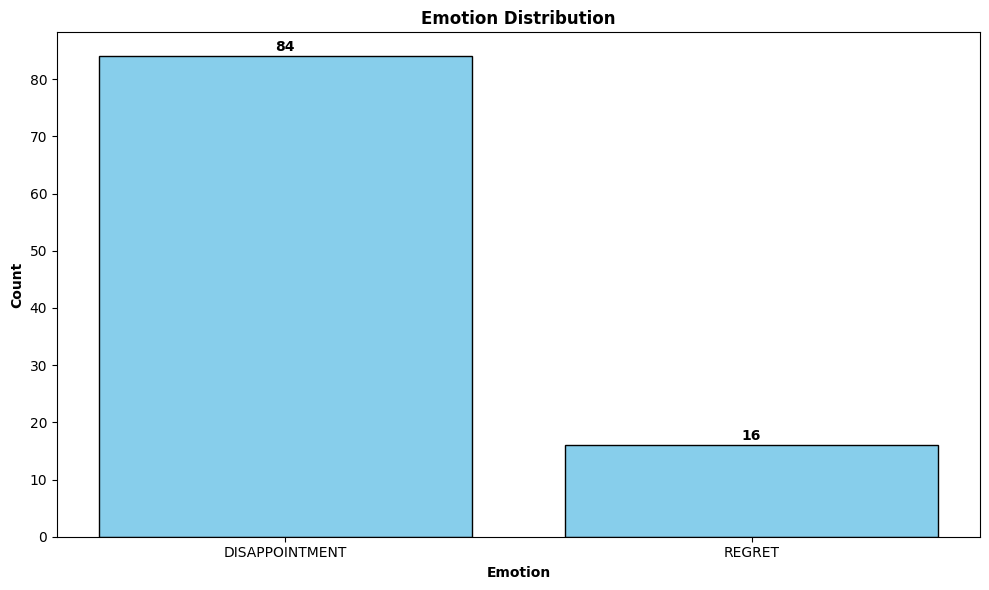

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
counts = df_results['result'].value_counts()
ax.bar(counts.index, counts.values, color='skyblue', edgecolor='black')
ax.set_xlabel('Emotion', fontweight='bold')
ax.set_ylabel('Count', fontweight='bold')
ax.set_title('Emotion Distribution', fontweight='bold')
for i, v in enumerate(counts.values):
    ax.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [15]:
## abc

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

In [17]:
# Set style for publication-quality plots
plt.style.use('seaborn-v0_8-paper')
sns.set_palette("husl")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9

In [18]:
# Load data
print("Loading data...")
df = pd.read_csv('/content/results_20251214_181118.csv')
df['reviews.date'] = pd.to_datetime(df['reviews.date'])

print(f"Total reviews: {len(df)}")
print(f"\nDataset Info:")
print(df.info())
print(f"\nEmotion Distribution:")
print(df['result'].value_counts())
print(f"\nBasic Statistics:")
print(df.describe())

# Create output directory
import os
os.makedirs('visualizations', exist_ok=True)

Loading data...
Total reviews: 100

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   id                 100 non-null    object             
 1   reviews.rating     100 non-null    int64              
 2   primaryCategories  100 non-null    object             
 3   reviews.text       100 non-null    object             
 4   reviews.date       99 non-null     datetime64[ns, UTC]
 5   result             100 non-null    object             
 6   confidence         100 non-null    float64            
 7   rds_score          100 non-null    float64            
dtypes: datetime64[ns, UTC](1), float64(2), int64(1), object(4)
memory usage: 6.4+ KB
None

Emotion Distribution:
result
DISAPPOINTMENT    84
REGRET            16
Name: count, dtype: int64

Basic Statistics:
       reviews.rating  confidence   rds

In [19]:
# ============================================================================
# VISUALIZATION 1: Emotion Distribution (Bar Chart)
# ============================================================================
print("\n[1/12] Creating emotion distribution chart...")
fig, ax = plt.subplots(figsize=(8, 6))

emotion_counts = df['result'].value_counts()
colors = ['#3498db', '#e74c3c', '#95a5a6']
bars = ax.bar(emotion_counts.index, emotion_counts.values,
              color=colors[:len(emotion_counts)],
              edgecolor='black', linewidth=1.5, alpha=0.8)

ax.set_xlabel('Emotion Classification', fontweight='bold')
ax.set_ylabel('Frequency', fontweight='bold')
ax.set_title('Distribution of Emotional Classifications in Customer Reviews',
             fontweight='bold', pad=20)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add value labels on bars
for i, (idx, v) in enumerate(emotion_counts.items()):
    percentage = (v / len(df)) * 100
    ax.text(i, v + 1, f'{v}\n({percentage:.1f}%)',
            ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/01_emotion_distribution.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 01_emotion_distribution.png")


[1/12] Creating emotion distribution chart...
✓ Saved: 01_emotion_distribution.png


In [20]:
# ============================================================================
# VISUALIZATION 2: RDS Score Distribution (Histogram with KDE)
# ============================================================================
print("[2/12] Creating RDS score distribution...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall distribution
axes[0].hist(df['rds_score'], bins=30, color='steelblue',
            edgecolor='black', alpha=0.7, density=True)
axes[0].axvline(0, color='red', linestyle='--', linewidth=2,
               label='Neutral (RDS=0)')
axes[0].axvline(df['rds_score'].mean(), color='green', linestyle='--',
               linewidth=2, label=f'Mean ({df["rds_score"].mean():.2f})')
axes[0].set_xlabel('RDS Differential Score', fontweight='bold')
axes[0].set_ylabel('Density', fontweight='bold')
axes[0].set_title('Overall RDS Score Distribution', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Add annotations
axes[0].text(0.05, 0.95, f'Mean: {df["rds_score"].mean():.2f}\nStd: {df["rds_score"].std():.2f}\nMedian: {df["rds_score"].median():.2f}',
            transform=axes[0].transAxes, fontsize=9,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Distribution by emotion
for emotion in df['result'].unique():
    if emotion != 'ERROR':
        data = df[df['result'] == emotion]['rds_score']
        axes[1].hist(data, bins=20, alpha=0.6, label=emotion, edgecolor='black')

axes[1].axvline(0, color='red', linestyle='--', linewidth=2,
               label='Neutral (RDS=0)')
axes[1].set_xlabel('RDS Differential Score', fontweight='bold')
axes[1].set_ylabel('Frequency', fontweight='bold')
axes[1].set_title('RDS Score Distribution by Emotion Type', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/02_rds_distribution.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 02_rds_distribution.png")

[2/12] Creating RDS score distribution...
✓ Saved: 02_rds_distribution.png


In [21]:
# ============================================================================
# VISUALIZATION 3: Emotion by Product Category (Stacked Bar)
# ============================================================================
print("[3/12] Creating emotion by category chart...")
fig, ax = plt.subplots(figsize=(12, 6))

# Create cross-tabulation
category_emotion = pd.crosstab(df['primaryCategories'], df['result'])
category_emotion.plot(kind='bar', stacked=True, ax=ax,
                     color=['#3498db', '#95a5a6', '#e74c3c'],
                     edgecolor='black', linewidth=1)

ax.set_xlabel('Product Category', fontweight='bold')
ax.set_ylabel('Number of Reviews', fontweight='bold')
ax.set_title('Emotion Distribution Across Product Categories',
            fontweight='bold', pad=20)
ax.legend(title='Emotion', loc='upper right')
plt.xticks(rotation=45, ha='right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/03_emotion_by_category.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 03_emotion_by_category.png")


[3/12] Creating emotion by category chart...
✓ Saved: 03_emotion_by_category.png


In [23]:
# ============================================================================
# VISUALIZATION 4: RDS Scores by Emotion (Box Plot)
# ============================================================================
print("[4/12] Creating RDS boxplot by emotion...")
fig, ax = plt.subplots(figsize=(10, 6))

# Filter out ERROR classifications
df_clean = df[df['result'] != 'ERROR']

positions = range(len(df_clean['result'].unique()))
bp = ax.boxplot([df_clean[df_clean['result'] == emotion]['rds_score']
                for emotion in df_clean['result'].unique()],
                labels=df_clean['result'].unique(),
                patch_artist=True,
                notch=True,
                showmeans=True)

# Color the boxes
colors = ['lightblue', 'lightcoral']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(0, color='red', linestyle='--', linewidth=2,
          label='Neutral (RDS=0)', alpha=0.7)
ax.set_ylabel('RDS Differential Score', fontweight='bold')
ax.set_xlabel('Emotion Classification', fontweight='bold')
ax.set_title('RDS Score Distribution by Emotion Classification',
            fontweight='bold', pad=20)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/04_rds_boxplot.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 04_rds_boxplot.png")

[4/12] Creating RDS boxplot by emotion...
✓ Saved: 04_rds_boxplot.png


In [24]:
# ============================================================================
# VISUALIZATION 5: Confidence Score Analysis
# ============================================================================
print("[5/12] Creating confidence score analysis...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confidence distribution
axes[0].hist(df['confidence'], bins=20, color='purple',
            edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Confidence Score', fontweight='bold')
axes[0].set_ylabel('Frequency', fontweight='bold')
axes[0].set_title('Distribution of Classification Confidence Scores',
                 fontweight='bold')
axes[0].grid(alpha=0.3)
axes[0].text(0.05, 0.95, f'Mean: {df["confidence"].mean():.3f}\nStd: {df["confidence"].std():.3f}',
            transform=axes[0].transAxes, fontsize=9,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Confidence by emotion
df_clean.boxplot(column='confidence', by='result', ax=axes[1],
                patch_artist=True)
axes[1].set_ylabel('Confidence Score', fontweight='bold')
axes[1].set_xlabel('Emotion Classification', fontweight='bold')
axes[1].set_title('Confidence Scores by Emotion Type', fontweight='bold')
plt.suptitle('')  # Remove default title

plt.tight_layout()
plt.savefig('visualizations/05_confidence_analysis.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 05_confidence_analysis.png")

[5/12] Creating confidence score analysis...
✓ Saved: 05_confidence_analysis.png


In [25]:
# ============================================================================
# VISUALIZATION 6: Rating vs RDS Score (Scatter + Regression)
# ============================================================================
print("[6/12] Creating rating vs RDS correlation...")
fig, ax = plt.subplots(figsize=(10, 6))

# Create scatter plot with different colors for emotions
colors_map = {'REGRET': '#e74c3c', 'DISAPPOINTMENT': '#3498db', 'ERROR': '#95a5a6'}
for emotion in df['result'].unique():
    mask = df['result'] == emotion
    ax.scatter(df[mask]['reviews.rating'], df[mask]['rds_score'],
              alpha=0.6, s=50, label=emotion, c=colors_map.get(emotion, 'gray'),
              edgecolors='black', linewidth=0.5)

# Add regression line
z = np.polyfit(df['reviews.rating'], df['rds_score'], 1)
p = np.poly1d(z)
ax.plot(df['reviews.rating'].sort_values(),
       p(df['reviews.rating'].sort_values()),
       "r--", linewidth=2, label=f'Regression (slope={z[0]:.2f})')

# Calculate correlation
corr = df['reviews.rating'].corr(df['rds_score'])
ax.text(0.05, 0.95, f'Pearson r = {corr:.3f}\np-value = {stats.pearsonr(df["reviews.rating"], df["rds_score"])[1]:.4f}',
       transform=ax.transAxes, fontsize=10,
       verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

ax.set_xlabel('Star Rating', fontweight='bold')
ax.set_ylabel('RDS Differential Score', fontweight='bold')
ax.set_title('Relationship Between Star Rating and RDS Score',
            fontweight='bold', pad=20)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/06_rating_rds_correlation.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 06_rating_rds_correlation.png")

[6/12] Creating rating vs RDS correlation...
✓ Saved: 06_rating_rds_correlation.png


In [26]:
# ============================================================================
# VISUALIZATION 7: Time Series Analysis
# ============================================================================
print("[7/12] Creating time series visualization...")
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Resample by month
df_sorted = df.sort_values('reviews.date')
df_sorted['year_month'] = df_sorted['reviews.date'].dt.to_period('M')

# Emotion counts over time
emotion_time = df_sorted.groupby(['year_month', 'result']).size().unstack(fill_value=0)
emotion_time.plot(ax=axes[0], marker='o', linewidth=2)
axes[0].set_xlabel('Month', fontweight='bold')
axes[0].set_ylabel('Number of Reviews', fontweight='bold')
axes[0].set_title('Emotion Classification Trends Over Time', fontweight='bold')
axes[0].legend(title='Emotion')
axes[0].grid(alpha=0.3)

# Average RDS over time
rds_time = df_sorted.groupby('year_month')['rds_score'].mean()
axes[1].plot(rds_time.index.astype(str), rds_time.values,
            marker='o', linewidth=2, color='purple')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2, alpha=0.5)
axes[1].set_xlabel('Month', fontweight='bold')
axes[1].set_ylabel('Average RDS Score', fontweight='bold')
axes[1].set_title('Average RDS Score Trend Over Time', fontweight='bold')
axes[1].grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('visualizations/07_time_series.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 07_time_series.png")

[7/12] Creating time series visualization...
✓ Saved: 07_time_series.png


In [27]:
# ============================================================================
# VISUALIZATION 8: Heatmap of Emotions by Category and Rating
# ============================================================================
print("[8/12] Creating heatmap...")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# REGRET heatmap
regret_data = df[df['result'] == 'REGRET']
regret_pivot = pd.crosstab(regret_data['primaryCategories'],
                          regret_data['reviews.rating'])
if not regret_pivot.empty:
    sns.heatmap(regret_pivot, annot=True, fmt='d', cmap='Reds',
               ax=axes[0], cbar_kws={'label': 'Count'})
    axes[0].set_title('REGRET: Category × Rating', fontweight='bold', pad=20)
    axes[0].set_xlabel('Star Rating', fontweight='bold')
    axes[0].set_ylabel('Product Category', fontweight='bold')

# DISAPPOINTMENT heatmap
disapp_data = df[df['result'] == 'DISAPPOINTMENT']
disapp_pivot = pd.crosstab(disapp_data['primaryCategories'],
                          disapp_data['reviews.rating'])
if not disapp_pivot.empty:
    sns.heatmap(disapp_pivot, annot=True, fmt='d', cmap='Blues',
               ax=axes[1], cbar_kws={'label': 'Count'})
    axes[1].set_title('DISAPPOINTMENT: Category × Rating', fontweight='bold', pad=20)
    axes[1].set_xlabel('Star Rating', fontweight='bold')
    axes[1].set_ylabel('Product Category', fontweight='bold')

plt.tight_layout()
plt.savefig('visualizations/08_heatmap_category_rating.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 08_heatmap_category_rating.png")

[8/12] Creating heatmap...
✓ Saved: 08_heatmap_category_rating.png


In [28]:
# ============================================================================
# VISUALIZATION 9: Statistical Comparison (T-test visualization)
# ============================================================================
print("[9/12] Creating statistical comparison...")
fig, ax = plt.subplots(figsize=(10, 6))

# Get RDS scores for each emotion
regret_scores = df[df['result'] == 'REGRET']['rds_score']
disapp_scores = df[df['result'] == 'DISAPPOINTMENT']['rds_score']

# Perform t-test
t_stat, p_value = stats.ttest_ind(regret_scores, disapp_scores)

# Create violin plot
data_for_violin = [regret_scores, disapp_scores]
positions = [1, 2]
parts = ax.violinplot(data_for_violin, positions=positions,
                     showmeans=True, showextrema=True)

# Color the violins
colors = ['#e74c3c', '#3498db']
for pc, color in zip(parts['bodies'], colors):
    pc.set_facecolor(color)
    pc.set_alpha(0.7)

ax.set_xticks(positions)
ax.set_xticklabels(['REGRET', 'DISAPPOINTMENT'])
ax.set_ylabel('RDS Differential Score', fontweight='bold')
ax.set_title('Statistical Comparison of RDS Scores by Emotion',
            fontweight='bold', pad=20)
ax.axhline(0, color='red', linestyle='--', linewidth=2, alpha=0.5,
          label='Neutral')
ax.grid(alpha=0.3, axis='y')

# Add statistical annotation
ax.text(0.5, 0.95,
       f't-statistic = {t_stat:.3f}\np-value = {p_value:.4f}\n{"Significant" if p_value < 0.05 else "Not significant"} (α=0.05)',
       transform=ax.transAxes, fontsize=11,
       verticalalignment='top', ha='center',
       bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7))

# Add means
ax.text(1, regret_scores.mean(), f'μ={regret_scores.mean():.2f}',
       ha='right', fontweight='bold', fontsize=9)
ax.text(2, disapp_scores.mean(), f'μ={disapp_scores.mean():.2f}',
       ha='left', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('visualizations/09_statistical_comparison.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 09_statistical_comparison.png")

[9/12] Creating statistical comparison...
✓ Saved: 09_statistical_comparison.png


In [29]:
# ============================================================================
# VISUALIZATION 10: Category-wise RDS Comparison
# ============================================================================
print("[10/12] Creating category-wise RDS comparison...")
fig, ax = plt.subplots(figsize=(12, 6))

# Calculate mean RDS by category and emotion
category_rds = df.groupby(['primaryCategories', 'result'])['rds_score'].mean().unstack()

category_rds.plot(kind='bar', ax=ax, color=['#3498db', '#95a5a6', '#e74c3c'],
                 edgecolor='black', linewidth=1, width=0.8)
ax.axhline(0, color='red', linestyle='--', linewidth=2, alpha=0.5)
ax.set_xlabel('Product Category', fontweight='bold')
ax.set_ylabel('Average RDS Score', fontweight='bold')
ax.set_title('Average RDS Scores by Category and Emotion',
            fontweight='bold', pad=20)
ax.legend(title='Emotion', loc='best')
plt.xticks(rotation=45, ha='right')
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('visualizations/10_category_rds_comparison.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 10_category_rds_comparison.png")

[10/12] Creating category-wise RDS comparison...
✓ Saved: 10_category_rds_comparison.png


In [30]:
# ============================================================================
# VISUALIZATION 11: Review Length Analysis
# ============================================================================
print("[11/12] Creating review length analysis...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Calculate review length
df['review_length'] = df['reviews.text'].str.len()

# Distribution by emotion
for emotion in df['result'].unique():
    if emotion != 'ERROR':
        data = df[df['result'] == emotion]['review_length']
        axes[0].hist(data, bins=20, alpha=0.6, label=emotion, edgecolor='black')

axes[0].set_xlabel('Review Length (characters)', fontweight='bold')
axes[0].set_ylabel('Frequency', fontweight='bold')
axes[0].set_title('Review Length Distribution by Emotion', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Boxplot
df.boxplot(column='review_length', by='result', ax=axes[1], patch_artist=True)
axes[1].set_ylabel('Review Length (characters)', fontweight='bold')
axes[1].set_xlabel('Emotion Classification', fontweight='bold')
axes[1].set_title('Review Length by Emotion Type', fontweight='bold')
plt.suptitle('')

plt.tight_layout()
plt.savefig('visualizations/11_review_length_analysis.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 11_review_length_analysis.png")

[11/12] Creating review length analysis...
✓ Saved: 11_review_length_analysis.png


In [31]:
# ============================================================================
# VISUALIZATION 12: Comprehensive Summary Dashboard
# ============================================================================
print("[12/12] Creating comprehensive summary dashboard...")
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Emotion pie chart
ax1 = fig.add_subplot(gs[0, 0])
emotion_counts.plot(kind='pie', ax=ax1, autopct='%1.1f%%',
                   colors=['#3498db', '#e74c3c', '#95a5a6'][:len(emotion_counts)],
                   startangle=90)
ax1.set_ylabel('')
ax1.set_title('Emotion Distribution', fontweight='bold')

# 2. RDS histogram
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df['rds_score'], bins=25, color='steelblue', edgecolor='black', alpha=0.7)
ax2.axvline(0, color='red', linestyle='--', linewidth=2)
ax2.set_xlabel('RDS Score')
ax2.set_title('RDS Distribution', fontweight='bold')
ax2.grid(alpha=0.3)

# 3. Confidence histogram
ax3 = fig.add_subplot(gs[0, 2])
ax3.hist(df['confidence'], bins=20, color='purple', edgecolor='black', alpha=0.7)
ax3.set_xlabel('Confidence')
ax3.set_title('Confidence Distribution', fontweight='bold')
ax3.grid(alpha=0.3)

# 4. Category breakdown
ax4 = fig.add_subplot(gs[1, :])
category_emotion.plot(kind='bar', stacked=True, ax=ax4,
                     color=['#3498db', '#95a5a6', '#e74c3c'],
                     edgecolor='black')
ax4.set_xlabel('Category')
ax4.set_ylabel('Count')
ax4.set_title('Emotions by Category', fontweight='bold')
plt.setp(ax4.xaxis.get_majorticklabels(), rotation=45, ha='right')

# 5. Rating distribution
ax5 = fig.add_subplot(gs[2, 0])
df['reviews.rating'].value_counts().sort_index().plot(kind='bar', ax=ax5,
                                                       color='orange', edgecolor='black')
ax5.set_xlabel('Rating')
ax5.set_ylabel('Count')
ax5.set_title('Rating Distribution', fontweight='bold')
ax5.grid(alpha=0.3, axis='y')

# 6. RDS by emotion boxplot (compact)
ax6 = fig.add_subplot(gs[2, 1])
df_clean.boxplot(column='rds_score', by='result', ax=ax6)
ax6.set_ylabel('RDS Score')
ax6.set_title('RDS by Emotion', fontweight='bold')
plt.suptitle('')

# 7. Summary statistics table
ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')

summary_stats = pd.DataFrame({
    'Metric': ['Total Reviews', 'Regret Count', 'Disappointment Count',
               'Avg Confidence', 'Avg RDS Score', 'RDS Std Dev'],
    'Value': [
        len(df),
        len(df[df['result'] == 'REGRET']),
        len(df[df['result'] == 'DISAPPOINTMENT']),
        f"{df['confidence'].mean():.3f}",
        f"{df['rds_score'].mean():.3f}",
        f"{df['rds_score'].std():.3f}"
    ]
})

table = ax7.table(cellText=summary_stats.values, colLabels=summary_stats.columns,
                 cellLoc='left', loc='center', bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)
ax7.set_title('Summary Statistics', fontweight='bold', pad=20)

plt.savefig('visualizations/12_comprehensive_dashboard.png', bbox_inches='tight')
plt.close()
print("✓ Saved: 12_comprehensive_dashboard.png")

[12/12] Creating comprehensive summary dashboard...
✓ Saved: 12_comprehensive_dashboard.png


In [32]:
import shutil
import os

# Define the directory to be zipped and the output zip file name
folder_to_zip = 'visualizations'
output_zip_file = 'visualizations'

# Check if the folder exists
if os.path.exists(folder_to_zip) and os.path.isdir(folder_to_zip):
    # Create the zip archive
    shutil.make_archive(output_zip_file, 'zip', folder_to_zip)
    print(f"✅ Successfully created '{output_zip_file}.zip' in the current directory.")
else:
    print(f"❌ Error: The folder '{folder_to_zip}' does not exist or is not a directory.")

# You can then download this file from the Colab file browser.


✅ Successfully created 'visualizations.zip' in the current directory.
